In [4]:
from typing_extensions import TypedDict

In [5]:
class State(TypedDict):
    graph_info:str

In [27]:
def start_play(state: State):
    print("Starting the play with graph info:", state["graph_info"])
    return {"graph_info": state["graph_info"]}

In [28]:
def play_badminton(state: State):
    print("Playing badminton with graph info:", state["graph_info"])
    return {"graph_info": state["graph_info"]}

In [29]:
def play_cricket(state: State):
    print("Playing cricket with graph info:", state["graph_info"])
    return {"graph_info": state["graph_info"]}

In [56]:
import random
from typing import Literal

def random_play(state: State)->Literal["play_badminton", "play_cricket"]:
    graph_info = state["graph_info"]
    print(random.random())
    if random.random() > 0.5:
        return "play_badminton"
    elif random.random() <= 0.5:
        return "play_cricket"
    else:
        raise ValueError("Invalid sport choice. Choose either 'badminton' or 'cricket'.")

In [57]:
from IPython.display import Image,display
from langgraph.graph import StateGraph, START,END

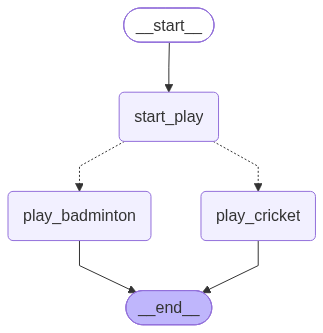

In [58]:
graph = StateGraph(State)
graph.add_node("start_play", start_play)
graph.add_node("play_badminton", play_badminton)
graph.add_node("play_cricket", play_cricket)

graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play",random_play)
graph.add_edge("play_badminton",END)
graph.add_edge("play_cricket",END)

graph_builder = graph.compile()

display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [61]:
graph_builder.invoke({"graph_info":"This is a simple graph for playing cricket sports."})

Starting the play with graph info: This is a simple graph for playing cricket sports.
0.026067781791939693
Playing badminton with graph info: This is a simple graph for playing cricket sports.


{'graph_info': 'This is a simple graph for playing cricket sports.'}